In [1]:
import numpy as np
import xarray as xr
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import cartopy.crs as ccrs
import regionmask
import seaborn as sns
from tqdm.auto import tqdm
from scipy import stats

ERROR 1: PROJ: proj_create_from_database: Open of /g/data/xp65/public/./apps/med_conda/envs/analysis3-25.09/share/proj failed


In [2]:
def plot_decorator():
    ax = plt.gca()
    
    # Minor ticks
    # ax.minorticks_on()
    # plt.tick_params(which='minor', axis='x', bottom=False)
    
    # Grid (light, behind data)
    ax.grid(color='gray', lw=0.4, alpha=0.1)
    
    # Remove top/right spines (Nature style)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    
    # Tight layout
    # plt.tight_layout()

In [3]:
import matplotlib as mpl

In [4]:
mpl.rcParams['font.family'] = 'Droid Sans'
mpl.rcParams['font.size'] = 14
# Edit axes parameters
mpl.rcParams['axes.linewidth'] = 0.8
# Tick properties
mpl.rcParams['xtick.major.size'] = 5
mpl.rcParams['xtick.minor.size'] = 3
mpl.rcParams['xtick.major.width'] = 1
mpl.rcParams['xtick.direction'] = 'out'
mpl.rcParams['ytick.major.size'] = 5
mpl.rcParams['ytick.minor.size'] = 3
mpl.rcParams['ytick.major.width'] = 1
mpl.rcParams['ytick.direction'] = 'out'

In [5]:
from matplotlib.colors import BoundaryNorm as BM
# from matplotlib.colors import LogNorm as LM
import matplotlib.patches as mpatches

In [6]:
from functions import preproc_funcs as funcs

In [41]:
base_path    = "/g/data/if69/as8561/data/enso_tele_robustness"
smile_models = [
    'ACCESS-ESM1-5', 'CESM1-CAM5', 'CSIRO-Mk3-6-0',
    'CanESM2', 'CanESM5_p1', 'GFDL-CM3', 'GFDL-ESM2M',
    'GFDL-SPEAR-MED', 'MIROC6', 'MPI-ESM',
]
clim_base = slice('1960', '1990')
baseline  = slice('1950', '2014')
clim_fut  = slice('2070', '2100')

In [8]:
tas_obs   = xr.open_dataset(f"{base_path}/tas_obs.nc").load()
pr_rean   = xr.open_dataset(f"{base_path}/pr_rean.nc").load()
nino34    = xr.open_dataset(f"{base_path}/nino34_index_hadisst.nc").load()
tas_cmip6 = xr.open_dataset(f"{base_path}/cmip6/ts_ssp5.nc").load()
pr_cmip6  = xr.open_dataset(f"{base_path}/cmip6/pr_ssp5.nc").load()

In [9]:
tas_smile, pr_smile = {}, {}

for m in tqdm(smile_models, desc='Loading SMILEs'):
    ts = xr.open_dataset(f"{base_path}/smiles/{m}_ts.nc", decode_times=False)
    pr = xr.open_dataset(f"{base_path}/smiles/{m}_pr.nc", decode_times=False)
    ts = xr.decode_cf(ts).convert_calendar('standard', use_cftime=False)
    pr = xr.decode_cf(pr).convert_calendar('standard', use_cftime=False)
    tas_smile[m] = ts.load()
    pr_smile[m]  = pr.load()

Loading SMILEs:   0%|          | 0/10 [00:00<?, ?it/s]

In [20]:
# Obs/rean/cmip6 — already anomalised, just detrend
tas_obs['tas']  = funcs.detrend_rolling_window(tas_obs['tas'],  window_size=15)
pr_rean['pr']   = funcs.detrend_rolling_window(pr_rean['pr'],   window_size=15)
tas_cmip6['ts'] = funcs.detrend_rolling_window(tas_cmip6['ts'], window_size=15)
pr_cmip6['pr']  = funcs.detrend_rolling_window(pr_cmip6['pr'],  window_size=15)

# SMILEs — anomaly then detrend
for m in tqdm(smile_models, desc='Processing SMILEs'):
    tas_smile[m] = tas_smile[m].rename({list(tas_smile[m].data_vars)[0]: 'ts'})
    pr_smile[m]  = pr_smile[m].rename({list(pr_smile[m].data_vars)[0]:  'pr'})

    tas_smile[m]['ts'] = funcs.detrend_rolling_window(
        funcs.calc_anom_annual(tas_smile[m]['ts'], tas_smile[m]['ts'].sel(time=clim_base)),
        window_size=15
    )
    pr_smile[m]['pr'] = funcs.detrend_rolling_window(
        funcs.calc_anom_annual(pr_smile[m]['pr'], pr_smile[m]['pr'].sel(time=clim_base)),
        window_size=15
    )

Processing SMILEs:   0%|          | 0/10 [00:00<?, ?it/s]

In [21]:
nino34_lat = slice(-5, 5)
nino34_lon = slice(190, 240)

nino34_obs          = nino34.rename({'tos': 'ts'})
nino34_obs['ts']    = funcs.detrend_rolling_window(nino34_obs['ts'], window_size=15)
nino34_cmip6        = tas_cmip6['ts'].sel(lat=nino34_lat, lon=nino34_lon).mean(['lat', 'lon'])
nino34_smile        = {m: tas_smile[m]['ts'].sel(lat=nino34_lat, lon=nino34_lon).mean(['lat', 'lon'])
                       for m in smile_models}

In [22]:
obs_std   = float(nino34_obs['ts'].sel(time=baseline).std('time'))
cmip6_std = nino34_cmip6.sel(time=baseline).std('time')

cond_en_obs  = nino34_obs['ts'] >  0.5 * obs_std
cond_ln_obs  = nino34_obs['ts'] < -0.5 * obs_std
cond_neu_obs = (nino34_obs['ts'] >= -0.25 * obs_std) & \
               (nino34_obs['ts'] <=  0.25 * obs_std)

cond_en_cmip6  = nino34_cmip6 >  0.5 * cmip6_std
cond_ln_cmip6  = nino34_cmip6 < -0.5 * cmip6_std
cond_neu_cmip6 = (nino34_cmip6 >= -0.25 * cmip6_std) & \
                 (nino34_cmip6 <=  0.25 * cmip6_std)

cond_en_smile, cond_ln_smile, cond_neu_smile = {}, {}, {}
for m in smile_models:
    smile_std         = nino34_smile[m].sel(time=baseline).std('time')
    cond_en_smile[m]  = nino34_smile[m] >  0.5 * smile_std
    cond_ln_smile[m]  = nino34_smile[m] < -0.5 * smile_std
    cond_neu_smile[m] = (nino34_smile[m] >= -0.25 * smile_std) & \
                        (nino34_smile[m] <=  0.25 * smile_std)

In [74]:
# --- AR6 masks ---
ar6_regions = regionmask.defined_regions.ar6.land
all_abbrevs = {r.abbrev: r.number for r in ar6_regions}

# --- Land masks ---
land_mask_obs   = regionmask.defined_regions.natural_earth_v5_0_0.land_10.mask_3D(tas_obs)
land_mask_rean  = regionmask.defined_regions.natural_earth_v5_0_0.land_10.mask_3D(pr_rean)
land_mask_cmip6 = regionmask.defined_regions.natural_earth_v5_0_0.land_10.mask_3D(tas_cmip6)
land_mask_smile = regionmask.defined_regions.natural_earth_v5_0_0.land_10.mask_3D(tas_smile['ACCESS-ESM1-5'])

# --- AR6 masks with land mask applied ---
ar6_mask_obs   = regionmask.defined_regions.ar6.land.mask_3D(tas_obs.where(land_mask_obs))
ar6_mask_rean  = regionmask.defined_regions.ar6.land.mask_3D(pr_rean.where(land_mask_rean))
ar6_mask_cmip6 = regionmask.defined_regions.ar6.land.mask_3D(tas_cmip6.where(land_mask_cmip6))
ar6_mask_smile = regionmask.defined_regions.ar6.land.mask_3D(tas_smile['ACCESS-ESM1-5'].where(land_mask_smile))

# --- Updated weighted regional mean function ---
def weighted_region(da, mask_3d, region_idx):
    """
    mask_3d: boolean (region, lat, lon) from mask_3D
    region_idx: integer index into mask_3d.region
    """
    weights  = np.cos(np.deg2rad(da.lat))
    region_mask = mask_3d.isel(region=region_idx)
    return da.where(region_mask).weighted(weights).mean(['lat', 'lon'])

In [75]:
tas_obs_reg, pr_rean_reg, tas_cmip6_reg, pr_cmip6_reg = {}, {}, {}, {}

for idx, (abbrev, rnum) in enumerate(tqdm(all_abbrevs.items(), desc='Obs/CMIP6 regions')):
    
    # find region index in mask_3D
    obs_idx   = int(np.where(ar6_mask_obs.region == rnum)[0])
    rean_idx  = int(np.where(ar6_mask_rean.region == rnum)[0])
    cmip6_idx = int(np.where(ar6_mask_cmip6.region == rnum)[0])

    tas_obs_reg[abbrev]   = weighted_region(tas_obs['tas'],   ar6_mask_obs,   obs_idx)
    
    da = weighted_region(pr_rean['pr'], ar6_mask_rean, rean_idx)
    pr_rean_reg[abbrev]   = da / float(da.std('time', skipna=True))

    tas_cmip6_reg[abbrev] = weighted_region(tas_cmip6['ts'], ar6_mask_cmip6, cmip6_idx)

    da = weighted_region(pr_cmip6['pr'], ar6_mask_cmip6, cmip6_idx)
    pr_cmip6_reg[abbrev]  = da / da.std('time', skipna=True)

# --- SMILEs ---
tas_smile_reg, pr_smile_reg = {}, {}

for m in tqdm(smile_models, desc='SMILE regions'):
    tas_smile_reg[m] = {}
    pr_smile_reg[m]  = {}
    for abbrev, rnum in all_abbrevs.items():
        smile_idx = int(np.where(ar6_mask_smile.region == rnum)[0])
        
        tas_smile_reg[m][abbrev] = weighted_region(tas_smile[m]['ts'], ar6_mask_smile, smile_idx)
        
        da = weighted_region(pr_smile[m]['pr'], ar6_mask_smile, smile_idx)
        pr_smile_reg[m][abbrev]  = da / da.std('time', skipna=True)

Obs/CMIP6 regions:   0%|          | 0/46 [00:00<?, ?it/s]

/scratch/gb02/as8561/tmp/ipykernel_3267759/4135298817.py:6: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  obs_idx   = int(np.where(ar6_mask_obs.region == rnum)[0])
/scratch/gb02/as8561/tmp/ipykernel_3267759/4135298817.py:7: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  rean_idx  = int(np.where(ar6_mask_rean.region == rnum)[0])
/scratch/gb02/as8561/tmp/ipykernel_3267759/4135298817.py:8: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  cmip6_idx = int(np.where(ar6_mask_

SMILE regions:   0%|          | 0/10 [00:00<?, ?it/s]

/scratch/gb02/as8561/tmp/ipykernel_3267759/4135298817.py:27: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  smile_idx = int(np.where(ar6_mask_smile.region == rnum)[0])
/scratch/gb02/as8561/tmp/ipykernel_3267759/4135298817.py:27: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  smile_idx = int(np.where(ar6_mask_smile.region == rnum)[0])
/scratch/gb02/as8561/tmp/ipykernel_3267759/4135298817.py:27: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  smile_idx = int(np.where(ar6

In [76]:
def rolling_composite(da, cond_en, cond_ln,
                       start=1900, end=2014, duration=30, gap=1):
    en_means, ln_means, yrs = [], [], []
    
    for yr in range(start, end - duration + 2, gap):
        win        = slice(str(yr), str(yr + duration - 1))
        en_sub     = da.sel(time=win).where(cond_en.sel(time=win), drop=True)
        ln_sub     = da.sel(time=win).where(cond_ln.sel(time=win), drop=True)
        
        en_means.append(float(en_sub.mean('time', skipna=True))
                        if en_sub.sizes['time'] > 2 else np.nan)
        ln_means.append(float(ln_sub.mean('time', skipna=True))
                        if ln_sub.sizes['time'] > 2 else np.nan)
        yrs.append(yr + duration - 1)
    
    return np.array(yrs), np.array(en_means), np.array(ln_means)

In [77]:
def comp_mean(da, cond):
    """Composite mean — NaN if no events."""
    sub = da.where(cond, drop=True)
    if sub.sizes['time'] < 2:
        return np.nan
    return float(sub.mean('time', skipna=True))

In [78]:
records = []

for abbrev in tqdm(all_abbrevs.keys(), desc='Regional composites'):

    # --- Obs ---
    tas_obs_r = tas_obs_reg[abbrev]
    pr_rean_r = pr_rean_reg[abbrev]

    tas_en_obs_base = float(tas_obs_r.sel(time=baseline).where(cond_en_obs.sel(time=baseline), drop=True).mean('time', skipna=True))
    tas_ln_obs_base = float(tas_obs_r.sel(time=baseline).where(cond_ln_obs.sel(time=baseline), drop=True).mean('time', skipna=True))
    pr_en_obs_base  = float(pr_rean_r.sel(time=baseline).where(cond_en_obs.sel(time=baseline), drop=True).mean('time', skipna=True))
    pr_ln_obs_base  = float(pr_rean_r.sel(time=baseline).where(cond_ln_obs.sel(time=baseline), drop=True).mean('time', skipna=True))

    _, tas_en_roll, tas_ln_roll = rolling_composite(tas_obs_r, cond_en_obs, cond_ln_obs)
    _, pr_en_roll,  pr_ln_roll  = rolling_composite(pr_rean_r, cond_en_obs, cond_ln_obs)

    # --- CMIP6 ---
    tas_c = tas_cmip6_reg[abbrev]
    pr_c  = pr_cmip6_reg[abbrev]

    tas_en_cmip6_base = float(tas_c.sel(time=baseline).where(cond_en_cmip6.sel(time=baseline)).mean(['time','model'], skipna=True))
    tas_ln_cmip6_base = float(tas_c.sel(time=baseline).where(cond_ln_cmip6.sel(time=baseline)).mean(['time','model'], skipna=True))
    tas_en_cmip6_fut  = float(tas_c.sel(time=clim_fut).where(cond_en_cmip6.sel(time=clim_fut)).mean(['time','model'],     skipna=True))
    tas_ln_cmip6_fut  = float(tas_c.sel(time=clim_fut).where(cond_ln_cmip6.sel(time=clim_fut)).mean(['time','model'],     skipna=True))

    pr_en_cmip6_base  = float(pr_c.sel(time=baseline).where(cond_en_cmip6.sel(time=baseline)).mean(['time','model'],  skipna=True))
    pr_ln_cmip6_base  = float(pr_c.sel(time=baseline).where(cond_ln_cmip6.sel(time=baseline)).mean(['time','model'],  skipna=True))
    pr_en_cmip6_fut   = float(pr_c.sel(time=clim_fut).where(cond_en_cmip6.sel(time=clim_fut)).mean(['time','model'],      skipna=True))
    pr_ln_cmip6_fut   = float(pr_c.sel(time=clim_fut).where(cond_ln_cmip6.sel(time=clim_fut)).mean(['time','model'],      skipna=True))

    # --- SMILE ---
    tas_en_base_s, tas_ln_base_s = [], []
    tas_en_fut_s,  tas_ln_fut_s  = [], []
    pr_en_base_s,  pr_ln_base_s  = [], []
    pr_en_fut_s,   pr_ln_fut_s   = [], []
    tas_en_iv_s,   tas_ln_iv_s   = [], []
    pr_en_iv_s,    pr_ln_iv_s    = [], []

    for m in smile_models:
        tas_s = tas_smile_reg[m][abbrev]
        pr_s  = pr_smile_reg[m][abbrev]

        tas_en_b = tas_s.sel(time=baseline).where(cond_en_smile[m].sel(time=baseline)).mean('time', skipna=True)
        tas_ln_b = tas_s.sel(time=baseline).where(cond_ln_smile[m].sel(time=baseline)).mean('time', skipna=True)
        tas_en_f = tas_s.sel(time=clim_fut).where(cond_en_smile[m].sel(time=clim_fut)).mean('time',     skipna=True)
        tas_ln_f = tas_s.sel(time=clim_fut).where(cond_ln_smile[m].sel(time=clim_fut)).mean('time',     skipna=True)

        pr_en_b  = pr_s.sel(time=baseline).where(cond_en_smile[m].sel(time=baseline)).mean('time',  skipna=True)
        pr_ln_b  = pr_s.sel(time=baseline).where(cond_ln_smile[m].sel(time=baseline)).mean('time',  skipna=True)
        pr_en_f  = pr_s.sel(time=clim_fut).where(cond_en_smile[m].sel(time=clim_fut)).mean('time',      skipna=True)
        pr_ln_f  = pr_s.sel(time=clim_fut).where(cond_ln_smile[m].sel(time=clim_fut)).mean('time',      skipna=True)

        tas_en_iv_s.append(float(tas_en_b.std('model', skipna=True)))
        tas_ln_iv_s.append(float(tas_ln_b.std('model', skipna=True)))
        pr_en_iv_s.append(float(pr_en_b.std('model',   skipna=True)))
        pr_ln_iv_s.append(float(pr_ln_b.std('model',   skipna=True)))

        tas_en_base_s.append(float(tas_en_b.mean('model', skipna=True)))
        tas_ln_base_s.append(float(tas_ln_b.mean('model', skipna=True)))
        tas_en_fut_s.append(float(tas_en_f.mean('model',  skipna=True)))
        tas_ln_fut_s.append(float(tas_ln_f.mean('model',  skipna=True)))
        pr_en_base_s.append(float(pr_en_b.mean('model',   skipna=True)))
        pr_ln_base_s.append(float(pr_ln_b.mean('model',   skipna=True)))
        pr_en_fut_s.append(float(pr_en_f.mean('model',    skipna=True)))
        pr_ln_fut_s.append(float(pr_ln_f.mean('model',    skipna=True)))

    records.append(dict(
        abbrev               = abbrev,
        name                 = ar6_regions[all_abbrevs[abbrev]].name,
        # Obs
        tas_en_obs_base      = tas_en_obs_base,
        tas_ln_obs_base      = tas_ln_obs_base,
        pr_en_obs_base       = pr_en_obs_base,
        pr_ln_obs_base       = pr_ln_obs_base,
        tas_en_roll          = tas_en_roll,
        tas_ln_roll          = tas_ln_roll,
        pr_en_roll           = pr_en_roll,
        pr_ln_roll           = pr_ln_roll,
        # CMIP6
        tas_en_cmip6_base    = tas_en_cmip6_base,
        tas_ln_cmip6_base    = tas_ln_cmip6_base,
        tas_en_cmip6_fut     = tas_en_cmip6_fut,
        tas_ln_cmip6_fut     = tas_ln_cmip6_fut,
        pr_en_cmip6_base     = pr_en_cmip6_base,
        pr_ln_cmip6_base     = pr_ln_cmip6_base,
        pr_en_cmip6_fut      = pr_en_cmip6_fut,
        pr_ln_cmip6_fut      = pr_ln_cmip6_fut,
        # SMILE IV
        tas_en_smile_iv      = np.nanmean(tas_en_iv_s),
        tas_ln_smile_iv      = np.nanmean(tas_ln_iv_s),
        pr_en_smile_iv       = np.nanmean(pr_en_iv_s),
        pr_ln_smile_iv       = np.nanmean(pr_ln_iv_s),
        # SMILE baseline
        tas_en_smile_base    = np.nanmean(tas_en_base_s),
        tas_ln_smile_base    = np.nanmean(tas_ln_base_s),
        pr_en_smile_base     = np.nanmean(pr_en_base_s),
        pr_ln_smile_base     = np.nanmean(pr_ln_base_s),
        # SMILE future
        tas_en_smile_fut_val = np.nanmean(tas_en_fut_s),
        tas_ln_smile_fut_val = np.nanmean(tas_ln_fut_s),
        pr_en_smile_fut_val  = np.nanmean(pr_en_fut_s),
        pr_ln_smile_fut_val  = np.nanmean(pr_ln_fut_s),
    ))

df = pd.DataFrame(records)
print(df[['abbrev', 'name', 'pr_en_obs_base', 'pr_en_cmip6_fut',
          'pr_en_smile_fut_val', 'pr_en_smile_base', 'pr_en_smile_iv']].head())

Regional composites:   0%|          | 0/46 [00:00<?, ?it/s]

  abbrev               name  pr_en_obs_base  pr_en_cmip6_fut  \
0    GIC  Greenland/Iceland       -0.218100        -0.180935   
1    NWN  N.W.North-America       -0.389554        -0.327285   
2    NEN  N.E.North-America       -0.160444        -0.171254   
3    WNA    W.North-America        0.248112         0.444879   
4    CNA    C.North-America        0.304981         0.415404   

   pr_en_smile_fut_val  pr_en_smile_base  pr_en_smile_iv  
0            -0.163652          0.045385        0.177783  
1            -0.519467         -0.169019        0.152306  
2            -0.439600         -0.081592        0.160444  
3             0.542229          0.257767        0.182399  
4             0.604635          0.598632        0.176078  


In [79]:
threshold = 1.5

for phase in ['en', 'ln']:
    for var in ['tas', 'pr']:
        
        # SMILE forced change — used as signal for both SNR tests
        smile_change = df[f'{var}_{phase}_smile_fut_val'] - df[f'{var}_{phase}_smile_base']

        # --- t-test ---
        df[f'{var}_{phase}_ttest'] = [ttest_cmip6(r, phase, var) for r in df.abbrev]

        # --- SNR obs — SMILE forced change vs obs 30-yr sampling std ---
        obs_noise = df[f'{var}_{phase}_roll'].apply(np.nanstd)
        df[f'{var}_{phase}_snr_obs'] = smile_change / obs_noise

        # --- SNR IV — SMILE forced change vs SMILE IV ---
        df[f'{var}_{phase}_snr_iv'] = smile_change / df[f'{var}_{phase}_smile_iv']

        # --- Robustness flags ---
        df[f'{var}_{phase}_rob_ttest'] = df[f'{var}_{phase}_ttest'] < 0.05
        df[f'{var}_{phase}_rob_obs']   = df[f'{var}_{phase}_snr_obs'].abs() > threshold
        df[f'{var}_{phase}_rob_iv']    = df[f'{var}_{phase}_snr_iv'].abs()  > threshold

print(df[['abbrev', 'pr_en_rob_ttest', 'pr_en_rob_obs', 'pr_en_rob_iv']].head(10))

  abbrev  pr_en_rob_ttest  pr_en_rob_obs  pr_en_rob_iv
0    GIC             True          False         False
1    NWN            False          False          True
2    NEN            False           True          True
3    WNA             True          False          True
4    CNA             True          False         False
5    ENA            False          False         False
6    NCA             True          False          True
7    SCA             True          False          True
8    CAR             True          False         False
9    NWS            False          False         False


In [166]:
df.to_csv('/g/data/if69/as8561/data/enso_tele_robustness/res/regional_summary_df.csv')

In [164]:
def plot_regional_summary_combined(df, var, title):
    
    # Sort by EN CMIP6 baseline — same order for both panels
    sort_col  = f'{var}_en_cmip6_base'
    df_sorted = df.sort_values(sort_col).reset_index(drop=True)
    n         = len(df_sorted)
    x         = np.arange(n)

    def get_color_cmip6(row, phase):
        return 'tab:red' if row[f'{var}_{phase}_rob_ttest'] else 'lightgrey'

    def get_color_smile(row, phase):
        iv  = row[f'{var}_{phase}_rob_iv']
        obs = row[f'{var}_{phase}_rob_obs']
        if iv and obs:  return 'tab:red'
        elif iv:        return 'tab:orange'
        else:           return 'lightgrey'

    fig, axes = plt.subplots(2, 1, figsize=(12, 10), sharex=True)

    for ax, phase, phase_label in zip(axes, ['en', 'ln'], ['El Niño', 'La Niña']):

        cmip6_colors = [get_color_cmip6(row, phase) for _, row in df_sorted.iterrows()]
        smile_colors = [get_color_smile(row, phase) for _, row in df_sorted.iterrows()]

        # --- Obs rolling boxplot ---
        roll_data = [arr[~np.isnan(arr)] for arr in df_sorted[f'{var}_{phase}_roll'].tolist()]
        ax.boxplot(
            roll_data,
            positions    = x,
            widths       = 0.5,
            patch_artist = True,
            boxprops     = dict(facecolor='lightgrey', alpha=0.7),
            medianprops  = dict(color='k', lw=1.5),
            whiskerprops = dict(lw=1.0),
            flierprops   = dict(marker='.', markersize=2, alpha=0.3),
            whis         = [5, 95],
            showfliers   = False,
            zorder       = 2,
        )

        # --- SMILE IV shading ---
        smile_base = df_sorted[f'{var}_{phase}_smile_base'].values
        iv_vals    = df_sorted[f'{var}_{phase}_smile_iv'].values
        ax.fill_between(x,
                        smile_base - iv_vals,
                        smile_base + iv_vals,
                        color='steelblue', alpha=0.2,
                        zorder=1)

        # --- CMIP6 baseline diamond ---
        cmip6_base = df_sorted[f'{var}_{phase}_cmip6_base'].values
        ax.scatter(x, cmip6_base,
                   marker='D', s=40, color='k', zorder=5)

        # --- CMIP6 future circle ---
        ax.scatter(x - 0.15, df_sorted[f'{var}_{phase}_cmip6_fut'].values,
                   marker='o', s=60, color=cmip6_colors,
                   edgecolors='k', linewidths=0.5, zorder=6)

        # --- SMILE future triangle ---
        ax.scatter(x + 0.15, df_sorted[f'{var}_{phase}_smile_fut_val'].values,
                   marker='^', s=70, color=smile_colors,
                   edgecolors='k', linewidths=0.5, zorder=6)

        ax.axhline(0, color='k', lw=0.5, linestyle='-')
        ax.set_xlim(-1.5, 46.5)
        ax.set_ylabel('Temp. anomaly (°C)' if var == 'tas' 
                      else 'Precip. anomaly (mm/month std$^{-1}$)')
        ax.set_title(f'{phase_label}')
        plt.sca(ax)
        plot_decorator()

        # Legend on first panel only
        if phase == 'en':
            from matplotlib.patches import Patch
            from matplotlib.lines import Line2D
            legend_elements = [
                Patch(facecolor='lightgrey', alpha=0.7,
                      label='Obs 30-yr sampling range (5th–95th)'),
                Patch(facecolor='steelblue', alpha=0.2,
                      label='SMILE IV (±1σ around SMILE baseline)'),
                Line2D([0], [0], marker='D', color='k',
                       linestyle='None', markersize=6,
                       label='CMIP6 baseline MMM'),
                Line2D([0], [0], marker='o', color='tab:red',
                       linestyle='None', markersize=6,
                       markeredgecolor='k', label='CMIP6 future — t-test robust'),
                Line2D([0], [0], marker='o', color='lightgrey',
                       linestyle='None', markersize=6,
                       markeredgecolor='k', label='CMIP6 future — not robust'),
                Line2D([0], [0], marker='^', color='tab:red',
                       linestyle='None', markersize=6,
                       markeredgecolor='k', label='SMILE future — IV + obs S/N robust'),
                Line2D([0], [0], marker='^', color='tab:orange',
                       linestyle='None', markersize=6,
                       markeredgecolor='k', label='SMILE future — IV only robust'),
                Line2D([0], [0], marker='^', color='lightgrey',
                       linestyle='None', markersize=6,
                       markeredgecolor='k', label='SMILE future — not robust'),
            ]
            # ax.legend(handles=legend_elements, fontsize=10,
            #           ncol=2, loc='lower right', frameon=False)

    # Shared x-axis labels on bottom panel only
    axes[1].set_xticks(x)
    axes[1].set_xticklabels(df_sorted['abbrev'].tolist(),
                             rotation=30, ha='center', fontsize=12,
                             rotation_mode='anchor')
    ticks = axes[1].xaxis.get_major_ticks()
    for i, tick in enumerate(ticks):
        if i % 2 == 0:
            tick.set_pad(30)
            tick.tick1line.set_markersize(30)
        else:
            tick.set_pad(2)
            tick.tick1line.set_markersize(5)

    fig.suptitle(title, fontsize=13, y=1.01)
    plt.tight_layout()
    # return fig


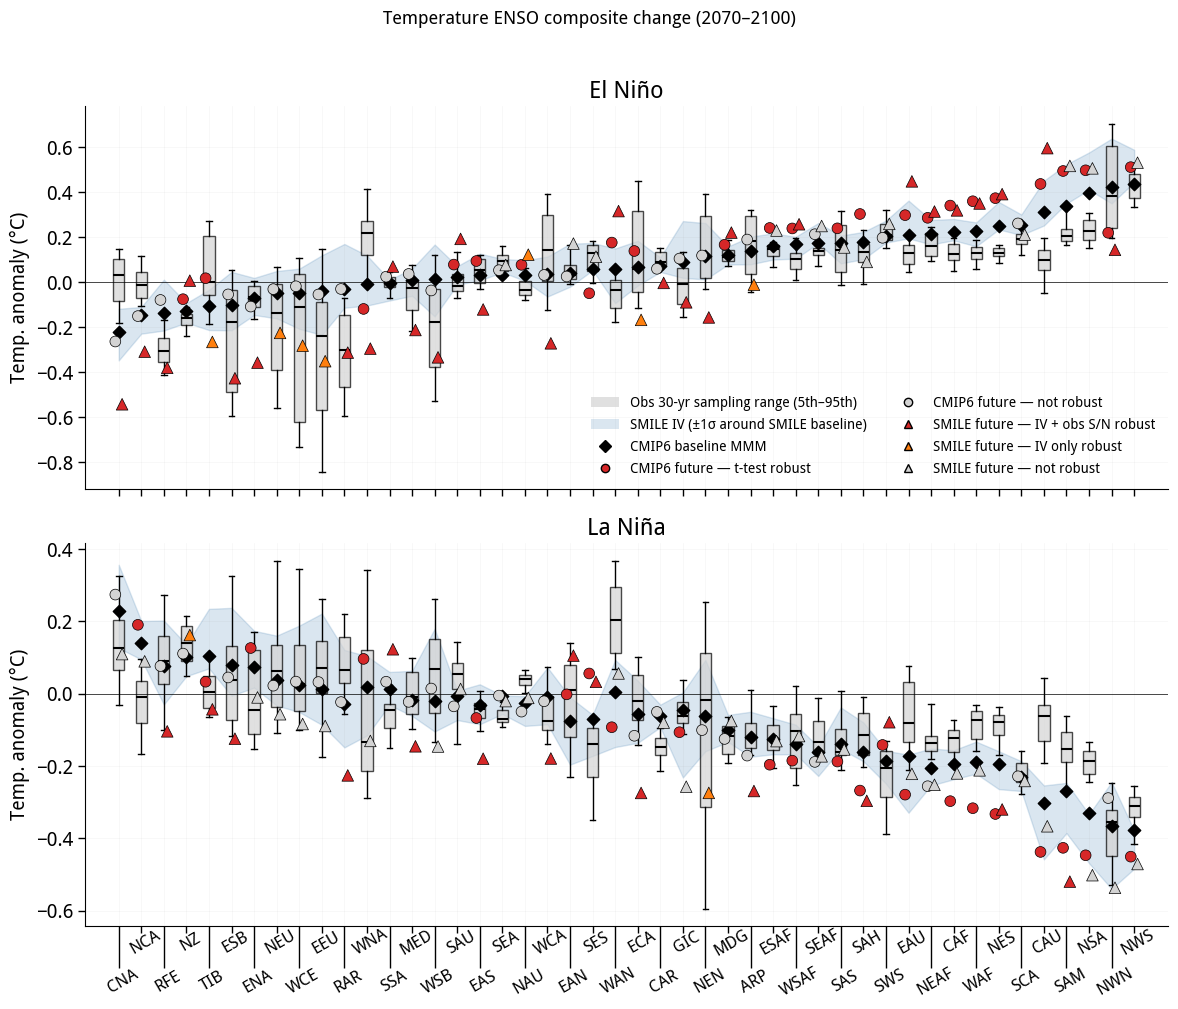

In [162]:
plot_regional_summary_combined(df, var='tas', title='Temperature ENSO composite change (2070–2100)')

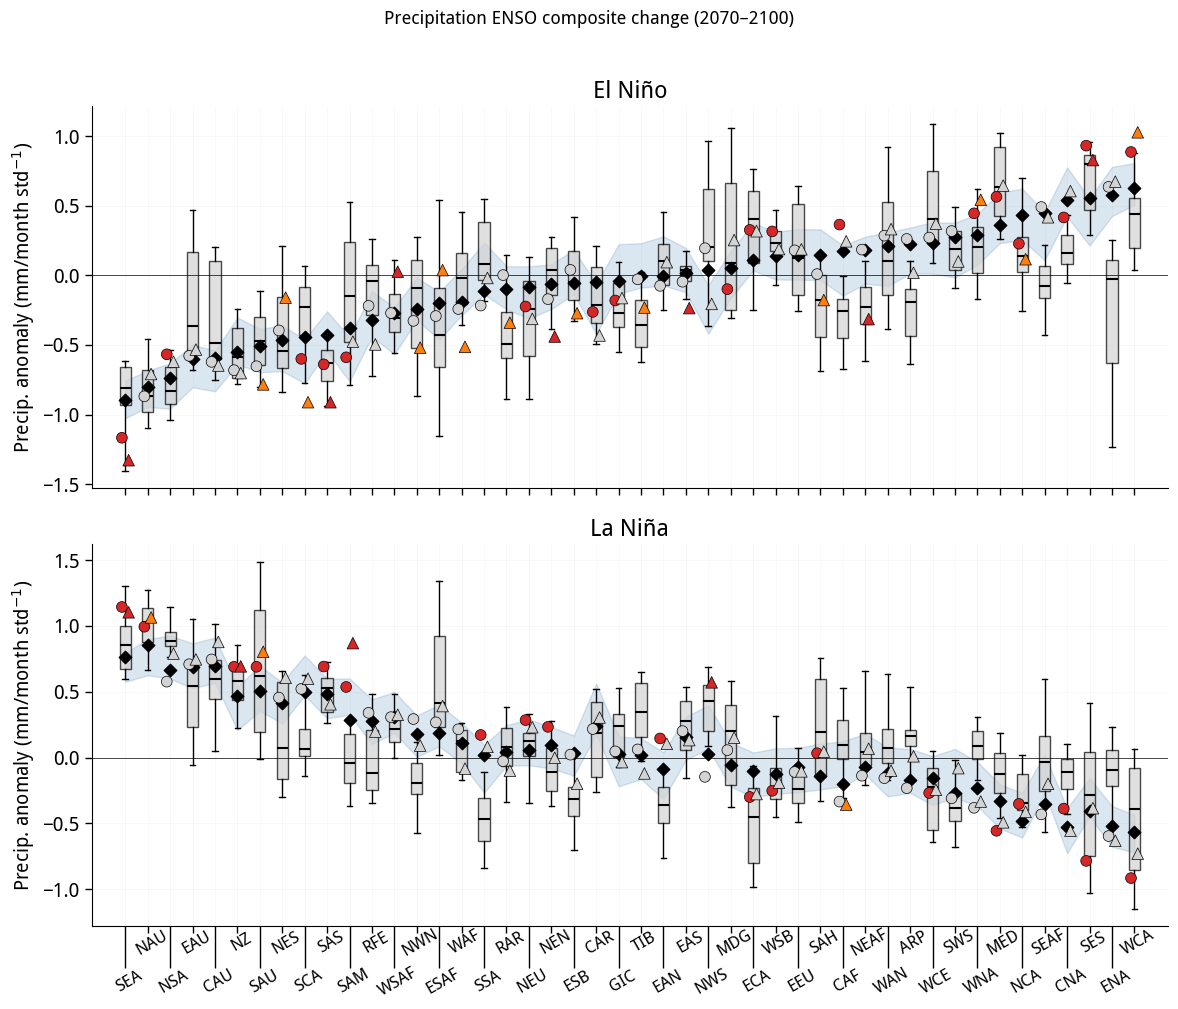

In [165]:
plot_regional_summary_combined(df, var='pr',  title='Precipitation ENSO composite change (2070–2100)')